# LAB1 - Phần 1 - Bài 2 (Trang 28): Khảo sát & tiền xử lý dữ liệu Bank Marketing
**Phạm Quốc Thuận - 6451071076 - CNTT.64**

Dữ liệu: `bank-full.csv` (45.211 dòng, 17 thuộc tính, phân cách bằng dấu `;`). Thuộc tính quyết định: `y` (khách hàng có đăng ký gửi tiền có kỳ hạn hay không).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
np.random.seed(42)

## Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính

In [2]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
df = pd.read_csv('../Dataset/bank/bank-full.csv', sep=';')
print('Kích thước dữ liệu:', df.shape)
display(df.head())
df.info()
display(df.describe())

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Kích thước dữ liệu: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## Câu 2: Liệt kê 5 thuộc tính có số lượng giá trị rỗng (unknown) nhiều nhất

In [3]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
print('Số giá trị NaN trong toàn bộ dữ liệu:', df.isnull().sum().sum())
# Dữ liệu bank dùng chuỗi 'unknown' để biểu diễn giá trị thiếu
unknown = (df == 'unknown').sum().sort_values(ascending=False)
percent = (unknown / len(df) * 100).round(1)
missing = pd.concat([unknown, percent], axis=1, keys=['Total', '%'])
missing.head(5)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số giá trị NaN trong toàn bộ dữ liệu: 0


,Total,%
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6
age,0,0.0


## Câu 3: Biểu đồ liên quan giữa Tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


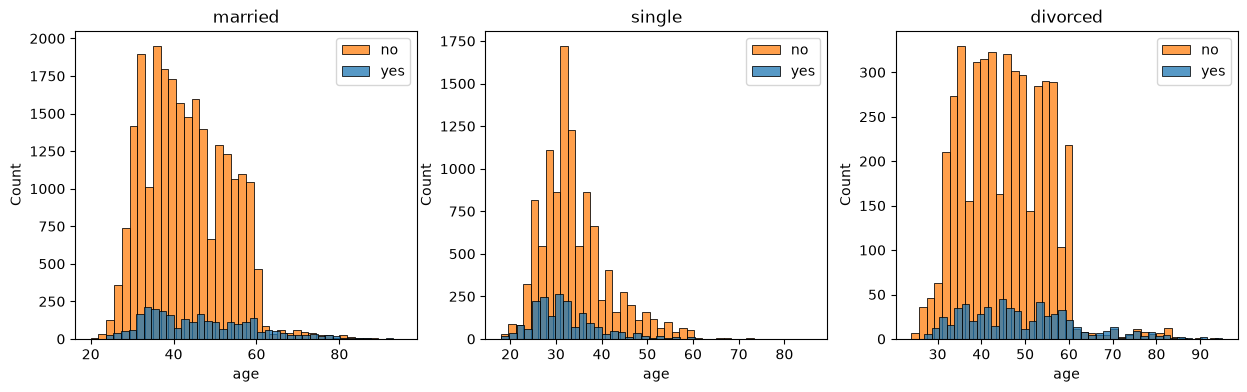

Tỉ lệ đăng ký theo marital:
marital
divorced    0.119
married     0.101
single      0.149
Name: y_num, dtype: float64

Tỉ lệ đăng ký theo nhóm tuổi:
age
(17, 25]     0.240
(25, 30]     0.145
(30, 40]     0.102
(40, 50]     0.091
(50, 60]     0.101
(60, 100]    0.423
Name: y_num, dtype: float64


In [4]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ['married', 'single', 'divorced']):
    d = df[df['marital'] == m]
    sns.histplot(d[d['y'] == 'no']['age'], bins=40, label='no', ax=ax, color='tab:orange')
    sns.histplot(d[d['y'] == 'yes']['age'], bins=40, label='yes', ax=ax, color='tab:blue')
    ax.set_title(m); ax.legend()
plt.show()
df['y_num'] = (df['y'] == 'yes').astype(int)
print('Tỉ lệ đăng ký theo marital:'); print(df.groupby('marital')['y_num'].mean().round(3))
bins = pd.cut(df['age'], [17, 25, 30, 40, 50, 60, 100])
print('\nTỉ lệ đăng ký theo nhóm tuổi:'); print(df.groupby(bins, observed=True)['y_num'].mean().round(3))

**Nhận xét:**
- Khách hàng **độc thân (single)** có tỉ lệ đăng ký cao nhất (14,9%), **đã kết hôn (married)** thấp nhất (10,1%).
- Nhóm tuổi **≤ 25 (24%)** và đặc biệt **> 60 tuổi (42,3%)** có tỉ lệ đăng ký cao vượt trội; nhóm 30–60 tuổi chỉ khoảng 9–10% dù chiếm phần lớn số khách hàng.
- => Tuổi và tình trạng hôn nhân có liên quan tới khả năng đăng ký gửi tiền có kỳ hạn.

## Câu 4: Liên quan giữa Học vấn (education), Khoản vay (loan) với y, phân biệt theo marital

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


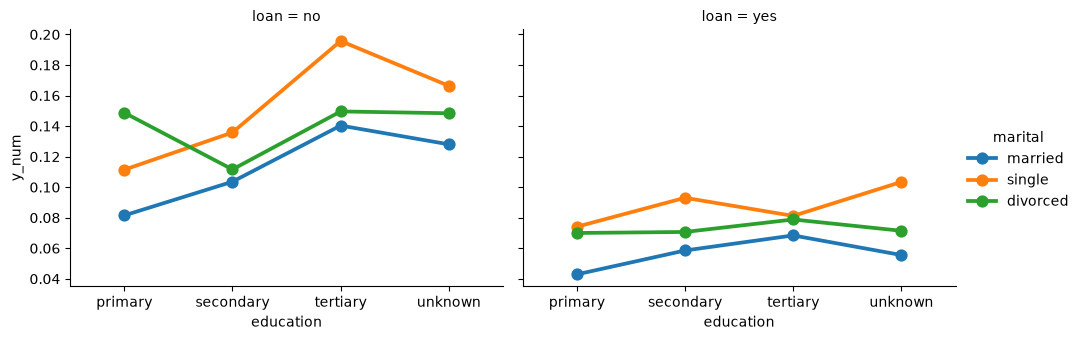

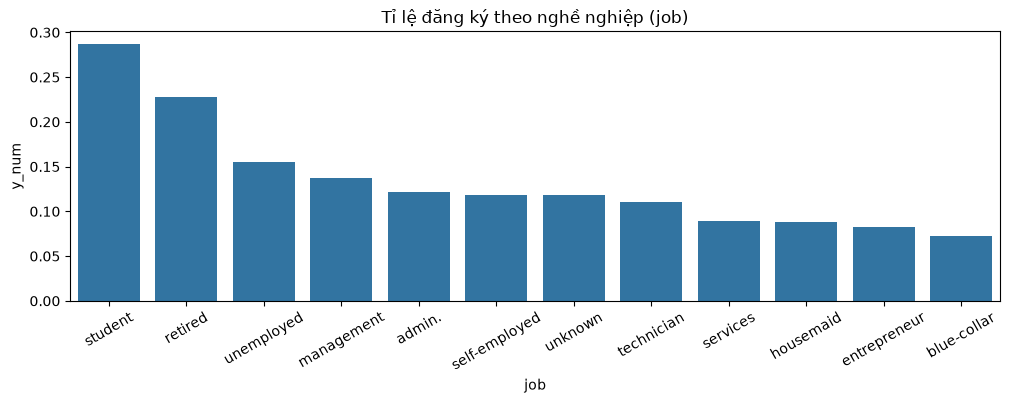

education
primary      0.086
secondary    0.106
tertiary     0.150
unknown      0.136
Name: y_num, dtype: float64
loan
no     0.127
yes    0.067
Name: y_num, dtype: float64


In [5]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
sns.catplot(data=df, x='education', y='y_num', hue='marital', col='loan', kind='point',
            order=['primary', 'secondary', 'tertiary', 'unknown'], height=3.5, aspect=1.4, errorbar=None)
plt.show()
plt.figure(figsize=(12, 3.5))
order = df.groupby('job')['y_num'].mean().sort_values(ascending=False).index
sns.barplot(data=df, x='job', y='y_num', order=order, errorbar=None)
plt.title('Tỉ lệ đăng ký theo nghề nghiệp (job)'); plt.xticks(rotation=30); plt.show()
print(df.groupby('education')['y_num'].mean().round(3))
print(df.groupby('loan')['y_num'].mean().round(3))

**Nhận xét:**
- Trình độ học vấn càng cao, tỉ lệ đăng ký càng cao: **tertiary (15%) > secondary (10,6%) > primary (8,6%)**; xu hướng này đúng ở cả 3 nhóm hôn nhân.
- Khách hàng **đang có khoản vay cá nhân (loan = yes)** có tỉ lệ đăng ký thấp hơn gần một nửa (6,7% so với 12,7%).
- Theo nghề nghiệp, **student (28,7%)** và **retired (22,8%)** đăng ký nhiều nhất; **blue-collar (7,3%)** thấp nhất.

## Câu 5: Thống kê số lần liên hệ (campaign) và liên quan với thuộc tính quyết định

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
Số khách hàng chỉ được liên hệ 1 lần : 17544
Số khách hàng được liên hệ nhiều lần: 27667


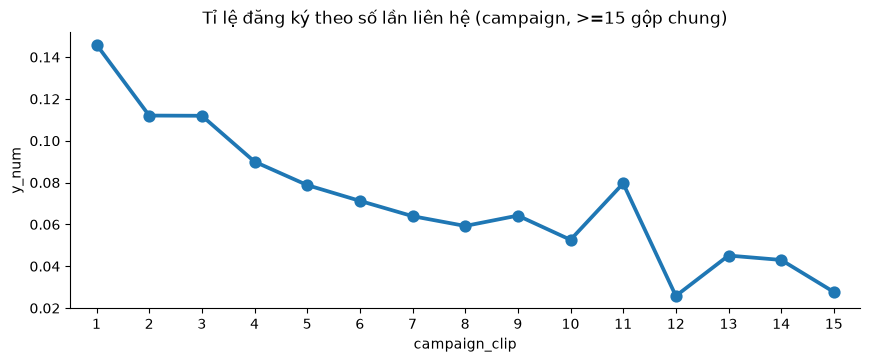

campaign_clip         1          2         3        4         5         6        7        8        9        10      11       12       13      14       15
count          17544.000  12505.000  5521.000  3522.00  1764.000  1291.000  735.000  540.000  327.000  266.000  201.00  155.000  133.000  93.000  614.000
mean               0.146      0.112     0.112     0.09     0.079     0.071    0.064    0.059    0.064    0.053    0.08    0.026    0.045   0.043    0.028


In [6]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
print('Số khách hàng chỉ được liên hệ 1 lần :', (df['campaign'] == 1).sum())
print('Số khách hàng được liên hệ nhiều lần:', (df['campaign'] > 1).sum())
df['campaign_clip'] = df['campaign'].clip(upper=15)   # gộp >15 lần vào nhóm 15
sns.catplot(data=df, x='campaign_clip', y='y_num', kind='point', height=3.5, aspect=2.5, errorbar=None)
plt.title('Tỉ lệ đăng ký theo số lần liên hệ (campaign, >=15 gộp chung)'); plt.show()
print(df.groupby('campaign_clip')['y_num'].agg(['count', 'mean']).round(3).T)
df = df.drop(columns=['campaign_clip'])

**Nhận xét:**
- Có **17.544** khách hàng chỉ được liên hệ 1 lần và **27.667** khách hàng được liên hệ nhiều lần.
- Tỉ lệ đăng ký **giảm dần khi số lần liên hệ tăng**: 14,6% (1 lần) → ~11% (2–3 lần) → dưới 3% (≥ 15 lần).
- => Liên hệ quá nhiều lần không giúp tăng khả năng đăng ký, ngân hàng nên tập trung vào vài lần liên hệ đầu.

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết

In [7]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# poutcome thiếu ~82%, contact thiếu ~29% và không ảnh hưởng nhiều -> xóa
# day (ngày trong tháng) không mang nhiều ý nghĩa -> xóa
df = df.drop(columns=['poutcome', 'contact', 'day'])

# job, education (categorical) -> điền bằng mode
for col in ['job', 'education']:
    mode = df.loc[df[col] != 'unknown', col].mode()[0]
    df[col] = df[col].replace('unknown', mode)
    print(f'{col}: điền unknown bằng "{mode}"')

print('\nSố giá trị unknown còn lại:'); print((df == 'unknown').sum().to_dict())
print('Số dòng trùng lặp:', df.duplicated().sum())
df.head()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64
job: điền unknown bằng "blue-collar"
education: điền unknown bằng "secondary"

Số giá trị unknown còn lại:
{'age': 0, 'job': 0, 'marital': 0, 'education': 0, 'default': 0, 'balance': 0, 'housing': 0, 'loan': 0, 'month': 0, 'duration': 0, 'campaign': 0, 'pdays': 0, 'previous': 0, 'y': 0, 'y_num': 0}
Số dòng trùng lặp: 0


,age,job,marital,education,default,balance,housing,loan,month,duration,campaign,pdays,previous,y,y_num
0,58,management,married,tertiary,no,2143,yes,no,may,261,1,-1,0,no,0
1,44,technician,single,secondary,no,29,yes,no,may,151,1,-1,0,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,may,76,1,-1,0,no,0
3,47,blue-collar,married,secondary,no,1506,yes,no,may,92,1,-1,0,no,0
4,33,blue-collar,single,secondary,no,1,no,no,may,198,1,-1,0,no,0


## Câu 7: Biến đổi các thuộc tính

In [8]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# 7.1 Thuộc tính nhị phân yes/no -> 1/0
for col in ['default', 'housing', 'loan', 'y']:
    df[col] = df[col].map({'no': 0, 'yes': 1})
df = df.drop(columns=['y_num'])

# 7.2 marital, education, month -> số
df['marital'] = df['marital'].map({'single': 0, 'married': 1, 'divorced': 2})
df['education'] = df['education'].map({'primary': 0, 'secondary': 1, 'tertiary': 2})
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
df['month'] = df['month'].map({m: i + 1 for i, m in enumerate(months)})

# 7.3 job (nominal, 11 giá trị) -> One-hot encoding để tránh quan hệ thứ bậc giả
df = pd.get_dummies(df, columns=['job'], prefix='job', dtype=int)

# 7.4 age -> 8 nhóm, balance -> 6 nhóm, duration -> 6 nhóm (số phần tử tương đối cân bằng)
df['age_group'] = pd.qcut(df['age'], 8, labels=False, duplicates='drop')
df['balance_group'] = pd.qcut(df['balance'], 6, labels=False, duplicates='drop')
df['duration_group'] = pd.qcut(df['duration'], 6, labels=False, duplicates='drop')
print('Ranh giới nhóm tuổi:', pd.qcut(df['age'], 8, retbins=True)[1])
print('Số lượng mỗi nhóm tuổi:', df['age_group'].value_counts().sort_index().to_dict())
print('Số lượng mỗi nhóm balance:', df['balance_group'].value_counts().sort_index().to_dict())
df.head()

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


Ranh giới nhóm tuổi: [18. 30. 33. 36. 39. 43. 48. 55. 95.]


Số lượng mỗi nhóm tuổi: {0: 7030, 1: 6053, 2: 5630, 3: 4649, 4: 5049, 5: 5612, 6: 6288, 7: 4900}
Số lượng mỗi nhóm balance: {0: 7631, 1: 7444, 2: 7533, 3: 7533, 4: 7535, 5: 7535}


,age,marital,education,default,balance,housing,loan,month,duration,campaign,pdays,previous,y,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,age_group,balance_group,duration_group
0,58,1,2,0,2143,1,0,5,261,1,-1,0,0,0,0,0,0,1,0,0,0,0,0,0,7,4,4
1,44,0,1,0,29,1,0,5,151,1,-1,0,0,0,0,0,0,0,0,0,0,0,1,0,5,1,2
2,33,1,1,0,2,1,1,5,76,1,-1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
3,47,1,1,0,1506,1,0,5,92,1,-1,0,0,0,1,0,0,0,0,0,0,0,0,0,5,4,1
4,33,0,1,0,1,0,0,5,198,1,-1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,3


## Câu 8: Tạo thuộc tính mới và chuẩn hóa Min-max

In [9]:
print("Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64")
# age_campaign: tích nhóm tuổi và số lần liên hệ
df['age_campaign'] = df['age_group'] * df['campaign']
# duration_per_campaign: thời lượng gọi trung bình mỗi lần liên hệ (làm trơn +1)
df['duration_per_campaign'] = (df['duration'] / (df['campaign'] + 1)).astype(int)

# Chuẩn hóa Min-max các thuộc tính số về [0, 1]
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
df_norm = df.copy()
df_norm[num_cols] = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())
display(df[['age_group', 'campaign', 'age_campaign', 'duration', 'duration_per_campaign', 'y']].head())
display(df_norm[num_cols].describe().loc[['min', 'max', 'mean']].round(3))

Họ tên: Phạm Quốc Thuận - MSSV: 6451071076 - Lớp: CNTT.64


,age_group,campaign,age_campaign,duration,duration_per_campaign,y
0,7,1,7,261,130,0
1,5,1,5,151,75,0
2,1,1,1,76,38,0
3,5,1,5,92,46,0
4,1,1,1,198,99,0


,age,balance,duration,campaign,pdays,previous
min,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000
mean,0.298,0.085,0.052,0.028,0.047,0.002
